# Session 11 · Reinforcement Learning Principles

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Hamnakhan123/Diploma-in-Data-Science/blob/main/term-2/03-advanced-data-science-with-python/code/session-11-reinforcement-learning-principles.ipynb)

Diploma in Data Science · Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run the cells from top to bottom. Every example is self-contained, so you can also run any single cell on its own.

### Example 1 · Basic: a three-state MDP and the Bellman equation by hand

In [1]:
"""A student's week as a 3-state MDP: evaluate a fixed policy exactly (linear algebra) and iteratively."""
import numpy as np

states = ["Study", "Social media", "Sleep"]
# Under the student's current policy, transition matrix P[s, s'] and expected reward R[s]
P = np.array([[0.5, 0.3, 0.2],
              [0.4, 0.5, 0.1],
              [0.6, 0.2, 0.2]])
R = np.array([+2.0, -1.0, +1.0])
gamma = 0.9

# Exact solution of V = R + gamma P V  ->  (I - gamma P) V = R
V_exact = np.linalg.solve(np.eye(3) - gamma * P, R)
print("exact values:", {st: round(float(v), 2) for st, v in zip(states, V_exact)})

# Iterative policy evaluation: repeat the Bellman expectation update
V = np.zeros(3)
for k in range(1, 200):
    V_new = R + gamma * P @ V
    if k in (1, 2, 3, 10, 50):
        print(f"sweep {k:>3}: {V_new.round(2)}")
    if np.max(np.abs(V_new - V)) < 1e-6:
        print(f"converged after {k} sweeps: {V_new.round(2)}")
        break
    V = V_new

# One Bellman update by hand for 'Study' using the exact values
s = 0
manual = R[s] + gamma * sum(P[s, j] * V_exact[j] for j in range(3))
print(f"\ncheck: V(Study) = 2 + 0.9 x (0.5 x {V_exact[0]:.2f} + 0.3 x {V_exact[1]:.2f} + 0.2 x {V_exact[2]:.2f}) = {manual:.2f}")

exact values: {'Study': 9.1, 'Social media': 5.52, 'Sleep': 8.43}
sweep   1: [ 2. -1.  1.]
sweep   2: [ 2.81 -0.64  2.08]
sweep   3: [ 3.47 -0.09  2.78]
sweep  10: [6.41 2.83 5.73]
sweep  50: [9.06 5.48 8.39]
converged after 130 sweeps: [9.1  5.52 8.43]

check: V(Study) = 2 + 0.9 x (0.5 x 9.10 + 0.3 x 5.52 + 0.2 x 8.43) = 9.10


### Example 2 · Intermediate: value iteration vs policy iteration on a stochastic grid

In [2]:
"""Value iteration and policy iteration on a 4x4 slippery grid world with a trap; compare iterations and time."""
import time
import numpy as np

N, GOAL, TRAP = 4, 15, 5
ACTIONS = ["^", ">", "v", "<"]
MOVES = [(-1, 0), (0, 1), (1, 0), (0, -1)]
gamma, slip = 0.95, 0.2                          # 20% of the time the agent slips sideways

def move(s, a):
    r, c = divmod(s, N); dr, dc = MOVES[a]
    r2, c2 = min(max(r + dr, 0), N - 1), min(max(c + dc, 0), N - 1)
    return r2 * N + c2

# Build P[s, a] as a list of (prob, next_state, reward, done)
P = {}
for s in range(N * N):
    for a in range(4):
        outcomes = []
        for prob, aa in [(1 - slip, a), (slip / 2, (a + 1) % 4), (slip / 2, (a + 3) % 4)]:
            s2 = s if s in (GOAL, TRAP) else move(s, aa)
            rew = 0 if s in (GOAL, TRAP) else (10 if s2 == GOAL else -10 if s2 == TRAP else -0.5)
            outcomes.append((prob, s2, rew, s2 in (GOAL, TRAP)))
        P[s, a] = outcomes

def q_from_v(V, s):
    return np.array([sum(p * (r + gamma * V[s2] * (not d)) for p, s2, r, d in P[s, a]) for a in range(4)])

def value_iteration(theta=1e-6):
    V, sweeps = np.zeros(N * N), 0
    while True:
        sweeps += 1
        V_new = np.array([q_from_v(V, s).max() for s in range(N * N)])
        if np.max(np.abs(V_new - V)) < theta:
            return V_new, np.array([q_from_v(V_new, s).argmax() for s in range(N * N)]), sweeps
        V = V_new

def policy_iteration():
    pi, rounds, evals = np.zeros(N * N, int), 0, 0
    while True:
        rounds += 1
        V = np.zeros(N * N)
        while True:                                   # policy evaluation
            evals += 1
            V_new = np.array([q_from_v(V, s)[pi[s]] for s in range(N * N)])
            if np.max(np.abs(V_new - V)) < 1e-6: break
            V = V_new
        new_pi = np.array([q_from_v(V, s).argmax() for s in range(N * N)])   # improvement
        if np.array_equal(new_pi, pi):
            return V, pi, rounds, evals
        pi = new_pi

def show(pi, V):
    for r in range(N):
        row = ""
        for c in range(N):
            s = r * N + c
            row += " G " if s == GOAL else " X " if s == TRAP else f" {ACTIONS[pi[s]]} "
        print(row + "   " + " ".join(f"{V[r * N + c]:6.2f}" for c in range(N)))

t0 = time.perf_counter(); V1, pi1, sweeps = value_iteration(); t1 = time.perf_counter() - t0
t0 = time.perf_counter(); V2, pi2, rounds, evals = policy_iteration(); t2 = time.perf_counter() - t0
print(f"value iteration : {sweeps} sweeps, {t1 * 1000:.0f} ms")
print(f"policy iteration: {rounds} improvement rounds ({evals} evaluation sweeps in total), {t2 * 1000:.0f} ms")
both_optimal = all(np.isclose(q_from_v(V1, s)[pi2[s]], q_from_v(V1, s).max()) for s in range(N * N))
print("max value difference:", float(np.abs(V1 - V2).max().round(5)),
      "| identical arrows:", bool(np.array_equal(pi1, pi2)), "| both policies optimal:", both_optimal)
# (arrows can differ only where two actions are exactly tied, e.g. the goal and trap cells)
print("\noptimal policy (X = trap, G = goal) and state values:")
show(pi1, V1)

value iteration : 29 sweeps, 3 ms
policy iteration: 5 improvement rounds (638 evaluation sweeps in total), 92 ms
max value difference: 0.0 | identical arrows: False | both policies optimal: True

optimal policy (X = trap, G = goal) and state values:
 >  >  >  v      2.78   3.53   6.11   7.03
 v  X  >  v      3.53   0.00   7.16   8.27
 v  v  >  v      6.11   7.16   8.40   9.61
 >  >  >  G      7.03   8.27   9.61   0.00


### Example 3 · Intermediate: Q-learning step by step with a TD-error trace

In [3]:
"""Q-learning on the same slippery grid without knowing the model; trace one update and compare with Q*."""
import numpy as np

N, GOAL, TRAP, gamma, slip = 4, 15, 5, 0.95, 0.2
MOVES = [(-1, 0), (0, 1), (1, 0), (0, -1)]
def env_step(s, a, rng):
    r = rng.random()
    a = a if r < 1 - slip else (a + 1) % 4 if r < 1 - slip / 2 else (a + 3) % 4
    row, col = divmod(s, N); dr, dc = MOVES[a]
    s2 = min(max(row + dr, 0), N - 1) * N + min(max(col + dc, 0), N - 1)
    if s2 == GOAL: return s2, 10.0, True
    if s2 == TRAP: return s2, -10.0, True
    return s2, -0.5, False

rng = np.random.default_rng(0)
Q = np.zeros((N * N, 4)); alpha = 0.1
for ep in range(20000):
    s, eps = 0, max(0.05, 1 - ep / 8000)
    for t in range(100):
        a = rng.integers(4) if rng.random() < eps else int(np.argmax(Q[s]))
        s2, r, done = env_step(s, a, rng)
        target = r + gamma * Q[s2].max() * (not done)
        td_error = target - Q[s, a]
        if ep == 15000 and t < 3:
            print(f"ep {ep} step {t}: s={s} a={'^>v<'[a]} r={r:+.1f} s'={s2}  "
                  f"Q={Q[s, a]:.3f} target={target:.3f} TD error={td_error:+.3f}")
        Q[s, a] += alpha * td_error
        s = s2
        if done: break

print("\nlearned greedy policy:")
for row in range(N):
    print(" ".join("G" if row * N + c == GOAL else "X" if row * N + c == TRAP else "^>v<"[int(np.argmax(Q[row * N + c]))] for c in range(N)))
print("learned V(start) = max Q(0, a) =", Q[0].max().round(2))

ep 15000 step 0: s=0 a=v r=-0.5 s'=1  Q=2.749 target=1.724 TD error=-1.026
ep 15000 step 1: s=1 a=> r=-0.5 s'=1  Q=2.341 target=1.724 TD error=-0.617
ep 15000 step 2: s=1 a=> r=-0.5 s'=2  Q=2.279 target=5.430 TD error=+3.151

learned greedy policy:
> > > v
< X > v
v v > v
> > > G
learned V(start) = max Q(0, a) = 1.65


### Example 4 · Advanced: ε-greedy vs Softmax exploration

action values:       [  5.    4.5   1.  -20. ]
eps-greedy (0.2):    [0.85 0.05 0.05 0.05] <- the -20 action still gets 5%
softmax (tau=10  ):  [0.37  0.352 0.248 0.03 ]
softmax (tau=2   ):  [0.522 0.407 0.071 0.   ]
softmax (tau=0.5 ):  [0.731 0.269 0.    0.   ]
softmax (tau=0.1 ):  [0.993 0.007 0.    0.   ]


eps-greedy 0.1          average reward 1.181 | pulls of the disastrous arm: 20


decaying eps            average reward 1.220 | pulls of the disastrous arm: 19


softmax (decaying tau)  average reward 1.329 | pulls of the disastrous arm: 1


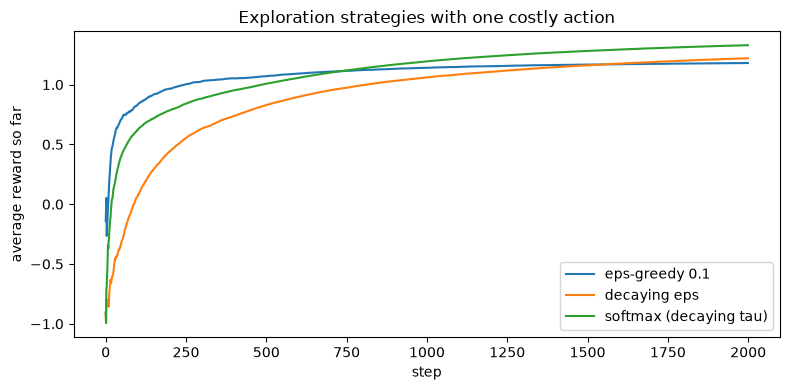

In [4]:
"""Exploration strategies: action probabilities under epsilon-greedy and softmax, then a learning comparison."""
import numpy as np
import matplotlib.pyplot as plt

Q = np.array([5.0, 4.5, 1.0, -20.0])                 # estimated values of 4 actions
def eps_greedy_probs(Q, eps):
    p = np.full(len(Q), eps / len(Q)); p[np.argmax(Q)] += 1 - eps; return p
def softmax_probs(Q, tau):
    z = (Q - Q.max()) / tau                          # subtract max for numerical stability
    e = np.exp(z); return e / e.sum()

print("action values:      ", Q)
print("eps-greedy (0.2):   ", eps_greedy_probs(Q, .2).round(3), "<- the -20 action still gets 5%")
for tau in [10, 2, 0.5, 0.1]:
    print(f"softmax (tau={tau:<4}): ", softmax_probs(Q, tau).round(3))

# Learning comparison on a 10-armed bandit with one disastrous arm
rng_master = np.random.default_rng(0)
def run(strategy, T=2000, seed=0):
    rng = np.random.default_rng(seed)
    means = rng.normal(0, 1, 10); means[3] = -10           # one very costly action
    Qh, N, total = np.zeros(10), np.zeros(10), np.zeros(T)
    for t in range(T):
        if strategy == "eps-greedy 0.1":
            a = rng.integers(10) if rng.random() < .1 else int(np.argmax(Qh))
        elif strategy == "decaying eps":
            a = rng.integers(10) if rng.random() < max(.01, 1 / (1 + t / 50)) else int(np.argmax(Qh))
        else:
            tau = max(.05, 1.0 * .998 ** t)                 # temperature decays from 1.0
            a = rng.choice(10, p=softmax_probs(Qh, tau))
        r = rng.normal(means[a], 1)
        N[a] += 1; Qh[a] += (r - Qh[a]) / N[a]; total[t] = r
    return total.cumsum() / np.arange(1, T + 1), N[3]

plt.figure(figsize=(8, 4))
for s in ["eps-greedy 0.1", "decaying eps", "softmax (decaying tau)"]:
    res = [run(s, seed=k) for k in range(100)]
    curve = np.mean([r[0] for r in res], axis=0); bad = np.mean([r[1] for r in res])
    print(f"{s:<23} average reward {curve[-1]:.3f} | pulls of the disastrous arm: {bad:.0f}")
    plt.plot(curve, label=s)
plt.xlabel("step"); plt.ylabel("average reward so far"); plt.title("Exploration strategies with one costly action")
plt.legend(); plt.tight_layout(); plt.savefig("session-11_exploration.png", dpi=110); plt.show()

### 🏙️ Real-life data problem: stock control for a pharmacy

expected daily demand: 3.13 boxes


value iteration converged in 292 sweeps
stock at night : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
optimal order  : [5, 5, 5, 5, 5, 0, 0, 0, 0, 0, 0]
order-up-to level implied: [5, 6, 7, 8, 9]

average daily profit by simulation:
  optimal MDP policy       Rs   302.9
  never order              Rs  -312.2
  always order 3           Rs   244.5
  order 5 when stock < 3   Rs   284.0



Q-learning policy: [5, 4, 5, 4, 5, 0, 0, 0, 0, 0, 1]
Q-learning daily profit: Rs 299.4


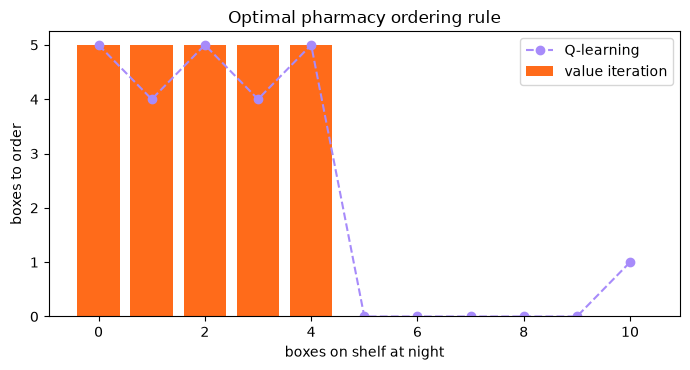

In [5]:
"""Real-life problem: pharmacy inventory as an MDP solved by value iteration, checked by simulation and Q-learning."""
import numpy as np
import matplotlib.pyplot as plt

CAP, MAX_ORDER, gamma = 10, 5, 0.95
PROFIT, HOLD, ORDER_FEE, LOST = 120, 8, 60, 100
demand_p = np.array([.05, .10, .20, .25, .20, .12, .08])          # P(demand = 0..6) per day
demand_vals = np.arange(len(demand_p))
print(f"expected daily demand: {demand_p @ demand_vals:.2f} boxes")

def outcome(stock, order, d):
    avail = min(CAP, stock + order)
    sold = min(avail, d)
    nxt = avail - sold
    reward = PROFIT * sold - HOLD * nxt - (ORDER_FEE if order > 0 else 0) - LOST * (d - sold)
    return nxt, reward

def q_values(V, s):
    return np.array([sum(p * (r + gamma * V[n]) for p, (n, r) in zip(demand_p, (outcome(s, a, d) for d in demand_vals)))
                     for a in range(MAX_ORDER + 1)])

V = np.zeros(CAP + 1)
for sweep in range(1000):
    V_new = np.array([q_values(V, s).max() for s in range(CAP + 1)])
    if np.abs(V_new - V).max() < 1e-4: break
    V = V_new
policy = np.array([q_values(V, s).argmax() for s in range(CAP + 1)])
print(f"value iteration converged in {sweep + 1} sweeps")
print("stock at night :", list(range(CAP + 1)))
print("optimal order  :", policy.tolist())
print("order-up-to level implied:", sorted(set((np.arange(CAP + 1) + policy)[policy > 0].tolist())))

def simulate(rule, days=20000, seed=1):
    rng = np.random.default_rng(seed); s, total = 5, 0.0
    for d in rng.choice(demand_vals, days, p=demand_p):
        s, r = outcome(s, rule(s), d); total += r
    return total / days

rules = {"optimal MDP policy": lambda s: policy[s], "never order": lambda s: 0,
         "always order 3": lambda s: 3, "order 5 when stock < 3": lambda s: 5 if s < 3 else 0}
print("\naverage daily profit by simulation:")
for name, rule in rules.items():
    print(f"  {name:<24} Rs {simulate(rule):7.1f}")

# Model-free check: Q-learning from simulated days only
rng = np.random.default_rng(3); Q = np.zeros((CAP + 1, MAX_ORDER + 1)); s = 5
for t in range(300_000):
    eps = max(.02, 1 - t / 150_000)
    a = rng.integers(MAX_ORDER + 1) if rng.random() < eps else int(Q[s].argmax())
    s2, r = outcome(s, a, rng.choice(demand_vals, p=demand_p))
    Q[s, a] += 0.05 * (r + gamma * Q[s2].max() - Q[s, a]); s = s2
print("\nQ-learning policy:", Q.argmax(axis=1).tolist())
print(f"Q-learning daily profit: Rs {simulate(lambda s: int(Q[s].argmax())):.1f}")

plt.figure(figsize=(7, 3.8))
plt.bar(range(CAP + 1), policy, color="#FF6B1A", label="value iteration")
plt.plot(range(CAP + 1), Q.argmax(axis=1), "o--", color="#A78BFA", label="Q-learning")
plt.xlabel("boxes on shelf at night"); plt.ylabel("boxes to order"); plt.title("Optimal pharmacy ordering rule")
plt.legend(); plt.tight_layout(); plt.savefig("session-11_pharmacy_policy.png", dpi=110); plt.show()

### 🧩 Mini project: when should a student study? (an MDP planner)

In [6]:
"""Mini project: plan a student's evening as an MDP over energy and hours left; solve with value iteration."""
import numpy as np

HOURS, ENERGY = 5, 4                       # hours left tonight (0..5), energy level (0..3)
ACTIONS = ["study", "rest", "scroll phone"]
gamma = 0.97

def transitions(h, e, a):
    """Return list of (prob, h', e', reward)."""
    if h == 0:
        return [(1.0, 0, e, 0.0)]
    if a == 0:   # study: learning depends on energy, costs energy
        learn = [0.0, 1.0, 2.5, 3.5][e]
        return [(0.8, h - 1, max(e - 1, 0), learn), (0.2, h - 1, e, learn)]
    if a == 1:   # rest: regain energy, small reward
        return [(0.9, h - 1, min(e + 1, ENERGY - 1), 0.3), (0.1, h - 1, e, 0.3)]
    return [(0.7, h - 1, e, 0.8), (0.3, h - 1, max(e - 1, 0), 0.8)]     # scrolling: fun now, sometimes tiring

V = np.zeros((HOURS + 1, ENERGY))
for _ in range(200):
    V_new = np.zeros_like(V)
    for h in range(HOURS + 1):
        for e in range(ENERGY):
            V_new[h, e] = max(sum(p * (r + gamma * V[h2, e2]) for p, h2, e2, r in transitions(h, e, a)) for a in range(3))
    if np.abs(V_new - V).max() < 1e-8: break
    V = V_new

print("optimal action by (hours left, energy):")
print("hours\\energy   " + "".join(f"{e:>14}" for e in range(ENERGY)))
for h in range(HOURS, 0, -1):
    best = [ACTIONS[int(np.argmax([sum(p * (r + gamma * V[h2, e2]) for p, h2, e2, r in transitions(h, e, a)) for a in range(3)]))] for e in range(ENERGY)]
    print(f"{h:>5}          " + "".join(f"{b:>14}" for b in best))
print(f"\nexpected value of an evening starting with 5 hours and energy 1: {V[5, 1]:.2f}")

optimal action by (hours left, energy):
hours\energy                0             1             2             3
    5                    rest          rest          rest         study
    4                    rest          rest          rest         study
    3                    rest          rest          rest         study
    2            scroll phone          rest         study         study
    1            scroll phone         study         study         study

expected value of an evening starting with 5 hours and energy 1: 7.44
